In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans,AgglomerativeClustering,DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score,davies_bouldin_score,calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram,linkage

#### Veri seti hakkında bilgiler edinelim

In [27]:
df = pd.read_csv("Data.csv")
print("Veri seti boyutu: ", df.shape)
df.info()

Veri seti boyutu:  (8950, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 

In [28]:
df.isnull().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [29]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


In [30]:
df.head(2)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.4,0.0,95.4,0.000000,0.166667,0.0,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.0,0.0,0.0,6442.945483,0.000000,0.0,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12


#### eksikleri ortalamayla dolduralım

In [31]:
df.set_index("CUST_ID",inplace=True)
imputer = SimpleImputer(strategy="mean")
df_imputed = pd.DataFrame(imputer.fit_transform(df),columns=df.columns,index=df.index)
print("Eksik değer kaldı mı:", df_imputed.isnull().sum().sum())

Eksik değer kaldı mı: 0


#### scale edelim

In [32]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_imputed)
df_scaled = pd.DataFrame(X_scaled,columns=df_imputed.columns,index=df_imputed.index)
df_scaled.head(2)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
CUST_ID,,,,,,,,,,,,,,,,,
C10001,-0.731989,-0.249434,-0.424900,-0.356934,-0.349079,-0.466786,-0.806490,-0.678661,-0.707313,-0.675349,-0.476070,-0.511333,-0.960433,-0.528979,-0.310968,-0.525551,0.36068
C10002,0.786961,0.134325,-0.469552,-0.356934,-0.454576,2.605605,-1.221758,-0.678661,-0.916995,0.573963,0.110074,-0.591796,0.688639,0.818642,0.089310,0.234227,0.36068


#### K-Means: elbow ve silhouette

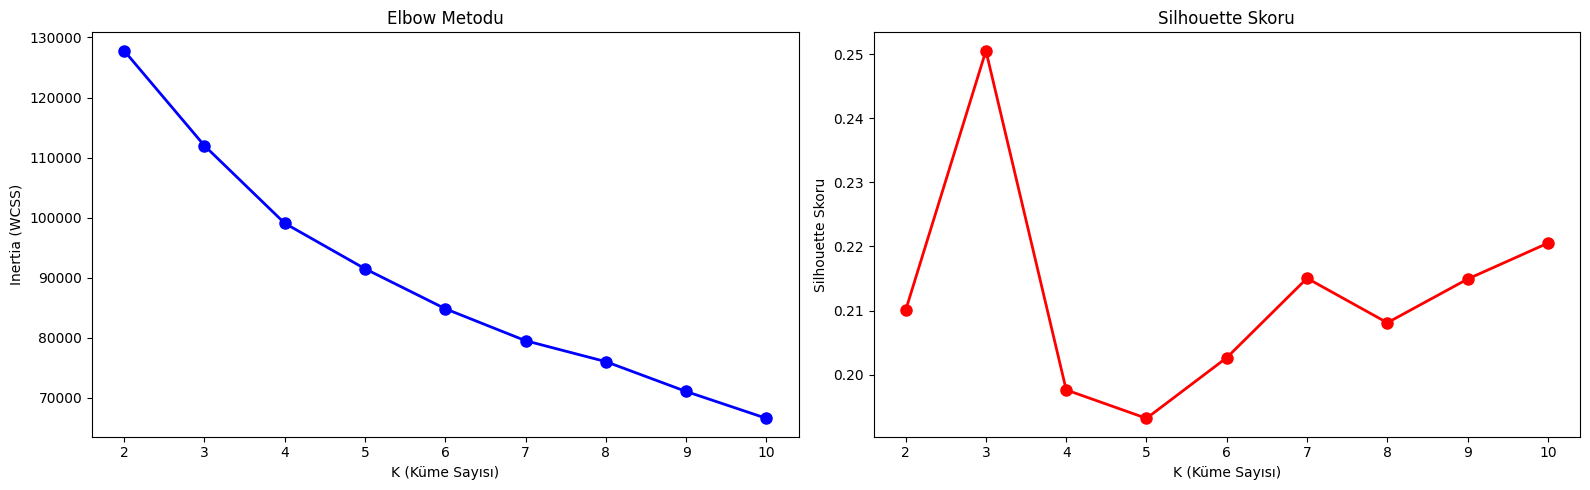

En iyi silhouette skoru: 0.25055570796307736
Optimum K: 3


In [33]:
inertia = []
silhouette_scores = []
K_range = range(2,11)

for k in K_range:
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled,labels))

fig, axes = plt.subplots(1,2,figsize=(16,5))
axes[0].plot(K_range,inertia,"bo-",linewidth=2,markersize=8)
axes[0].set_title("Elbow Metodu")
axes[0].set_xlabel("K (Küme Sayısı)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(K_range,silhouette_scores,"ro-",linewidth=2,markersize=8)
axes[1].set_title("Silhouette Skoru")
axes[1].set_xlabel("K (Küme Sayısı)")
axes[1].set_ylabel("Silhouette Skoru")
plt.tight_layout()
plt.show()

print("En iyi silhouette skoru:", max(silhouette_scores))
print("Optimum K:", K_range[np.argmax(silhouette_scores)])

In [34]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k,random_state=42,n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Küme sayısı:", optimal_k)
print("Silhouette Skoru:", silhouette_score(X_scaled,kmeans_labels))
print("Davies-Bouldin İndeksi:", davies_bouldin_score(X_scaled,kmeans_labels))
print("Calinski-Harabasz Skoru:", calinski_harabasz_score(X_scaled,kmeans_labels))
print(pd.Series(kmeans_labels).value_counts().sort_index())

Küme sayısı: 3
Silhouette Skoru: 0.25055570796307736
Davies-Bouldin İndeksi: 1.5972709940037866
Calinski-Harabasz Skoru: 1604.3967170808128
0    1596
1    1235
2    6119
Name: count, dtype: int64


#### PCA ile 2 boyutta görelim

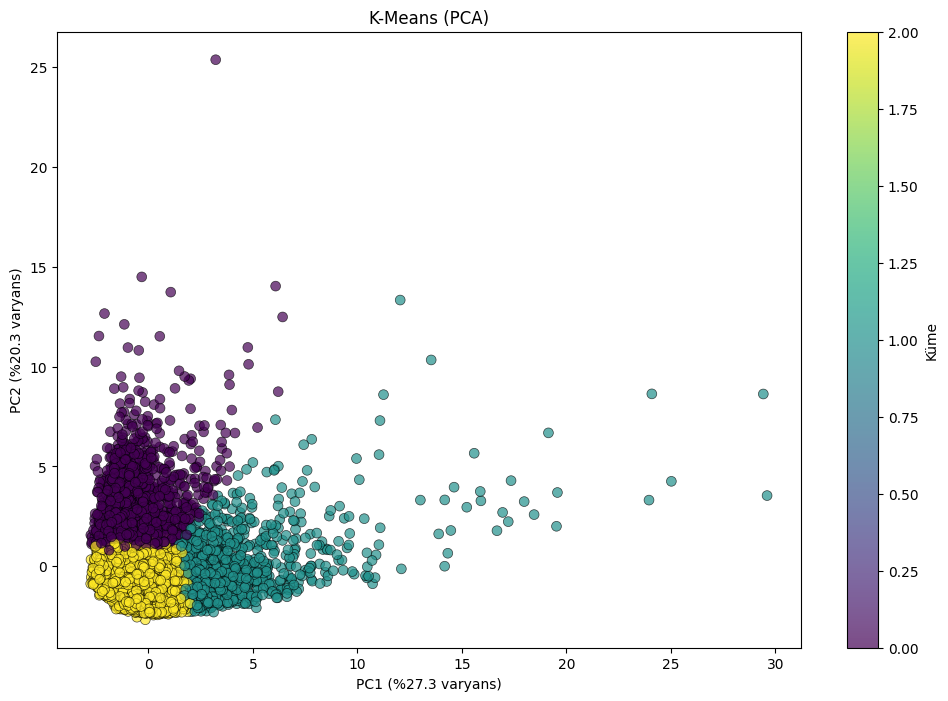

In [35]:
pca = PCA(n_components=2,random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12,8))
scatter = plt.scatter(X_pca[:,0],X_pca[:,1],c=kmeans_labels,cmap="viridis",alpha=0.7,s=50,edgecolors="k",linewidth=0.5)
plt.colorbar(scatter,label="Küme")
plt.title("K-Means (PCA)")
plt.xlabel(f"PC1 (%{pca.explained_variance_ratio_[0]*100:.1f} varyans)")
plt.ylabel(f"PC2 (%{pca.explained_variance_ratio_[1]*100:.1f} varyans)")
plt.show()

#### hiyerarşik kümeleme

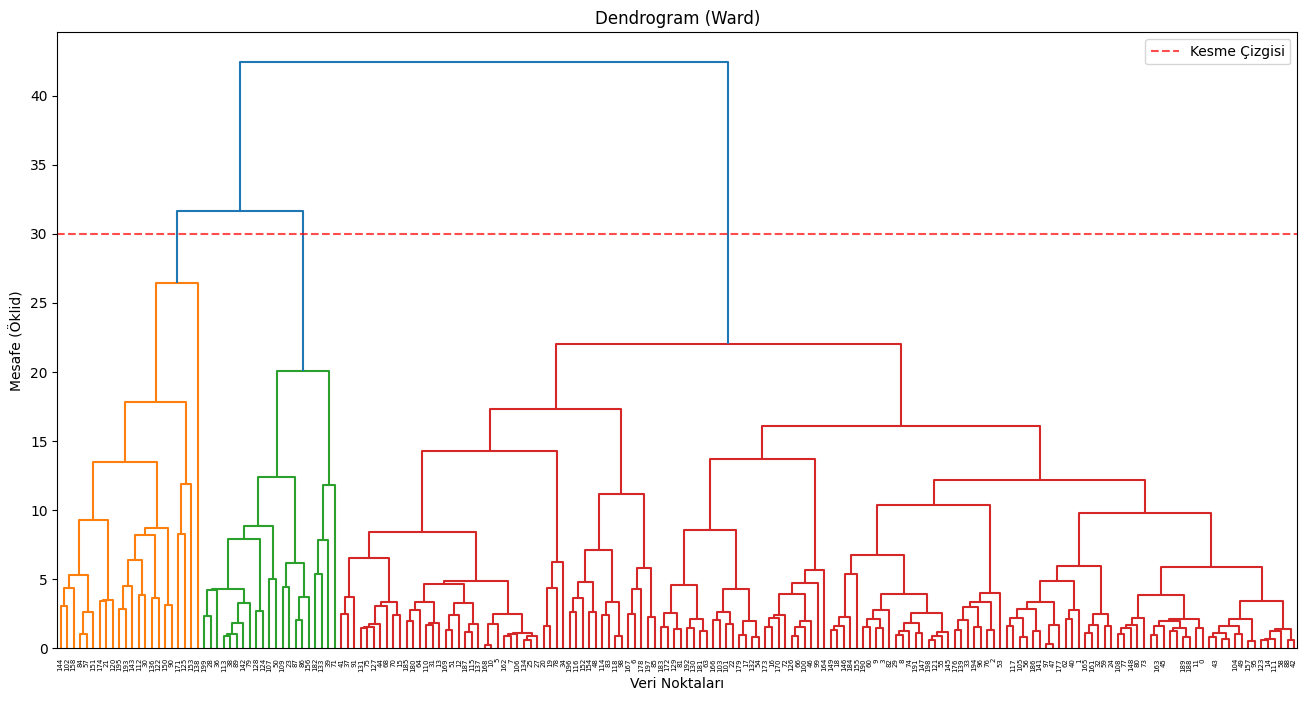

In [36]:
plt.figure(figsize=(16,8))
linked = linkage(X_scaled[:200],method="ward")
dendrogram(linked,orientation="top",distance_sort="descending",show_leaf_counts=False,truncate_mode="level",p=10)
plt.title("Dendrogram (Ward)")
plt.xlabel("Veri Noktaları")
plt.ylabel("Mesafe (Öklid)")
plt.axhline(y=30,color="r",linestyle="--",alpha=0.7,label="Kesme Çizgisi")
plt.legend()
plt.show()

In [37]:
agg_clustering = AgglomerativeClustering(n_clusters=optimal_k,linkage="ward")
agg_labels = agg_clustering.fit_predict(X_scaled)

print("Küme sayısı:", optimal_k)
print("Silhouette Skoru:", silhouette_score(X_scaled,agg_labels))
print("Davies-Bouldin İndeksi:", davies_bouldin_score(X_scaled,agg_labels))
print("Calinski-Harabasz Skoru:", calinski_harabasz_score(X_scaled,agg_labels))
print(pd.Series(agg_labels).value_counts().sort_index())

Küme sayısı: 3
Silhouette Skoru: 0.1731098007232828
Davies-Bouldin İndeksi: 1.797923175689862
Calinski-Harabasz Skoru: 1270.5039171504427
0    3418
1    4668
2     864
Name: count, dtype: int64


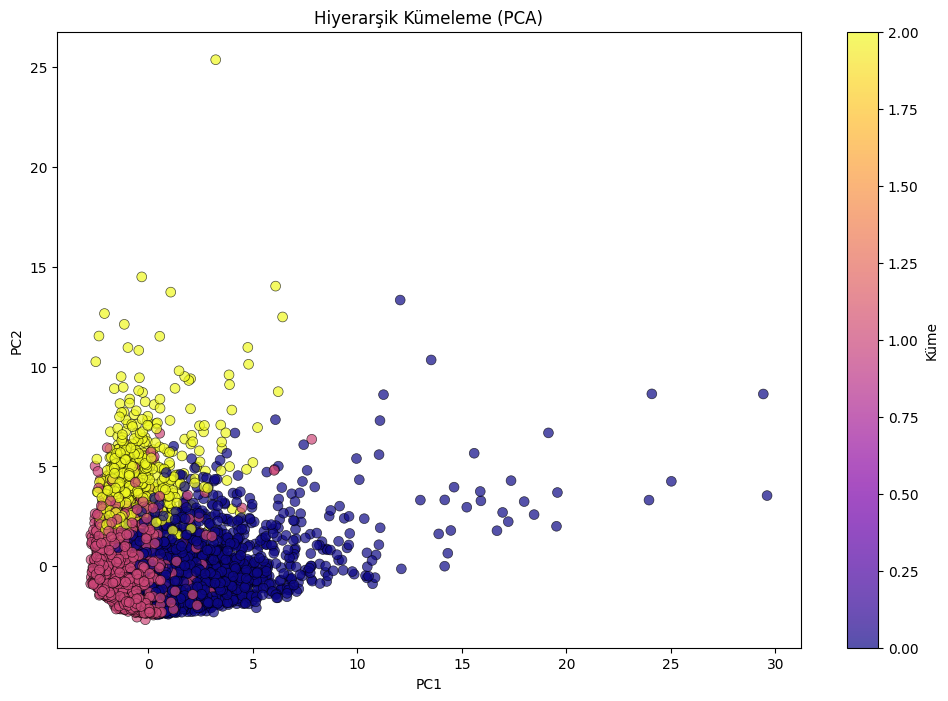

In [38]:
plt.figure(figsize=(12,8))
scatter = plt.scatter(X_pca[:,0],X_pca[:,1],c=agg_labels,cmap="plasma",alpha=0.7,s=50,edgecolors="k",linewidth=0.5)
plt.colorbar(scatter,label="Küme")
plt.title("Hiyerarşik Kümeleme (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

#### DBSCAN için eps seçelim

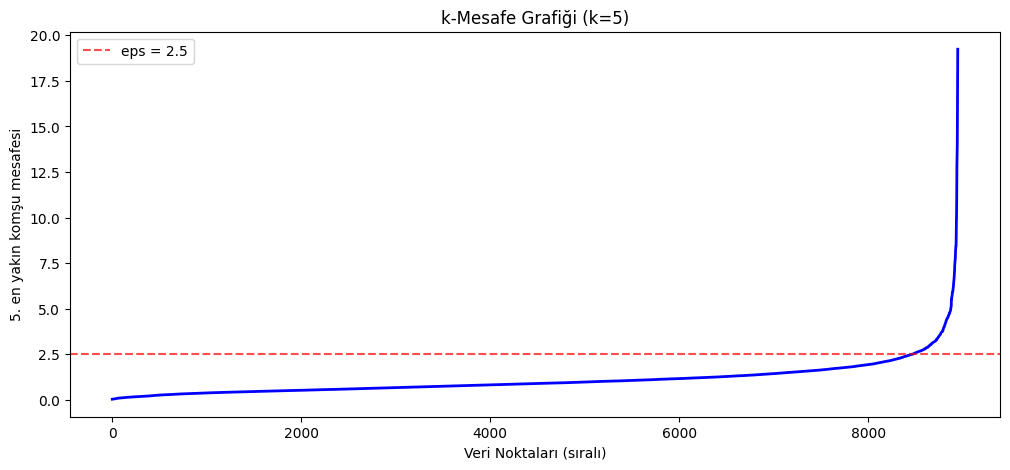

In [39]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:,4],axis=0)

plt.figure(figsize=(12,5))
plt.plot(distances,"b-",linewidth=2)
plt.axhline(y=2.5,color="r",linestyle="--",alpha=0.7,label="eps = 2.5")
plt.title("k-Mesafe Grafiği (k=5)")
plt.xlabel("Veri Noktaları (sıralı)")
plt.ylabel("5. en yakın komşu mesafesi")
plt.legend()
plt.show()

In [40]:
dbscan = DBSCAN(eps=2.5,min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(dbscan_labels))-(1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print("Küme sayısı:", n_clusters_db)
print("Gürültü sayısı:", n_noise)
print("Gürültü oranı:", n_noise/len(dbscan_labels))

if n_clusters_db > 1:
    print("Silhouette Skoru:", silhouette_score(X_scaled,dbscan_labels))
    print("Davies-Bouldin İndeksi:", davies_bouldin_score(X_scaled,dbscan_labels))
    print("Calinski-Harabasz Skoru:", calinski_harabasz_score(X_scaled,dbscan_labels))

print(pd.Series(dbscan_labels).value_counts().sort_index())

Küme sayısı: 1
Gürültü sayısı: 341
Gürültü oranı: 0.038100558659217874
-1     341
 0    8609
Name: count, dtype: int64


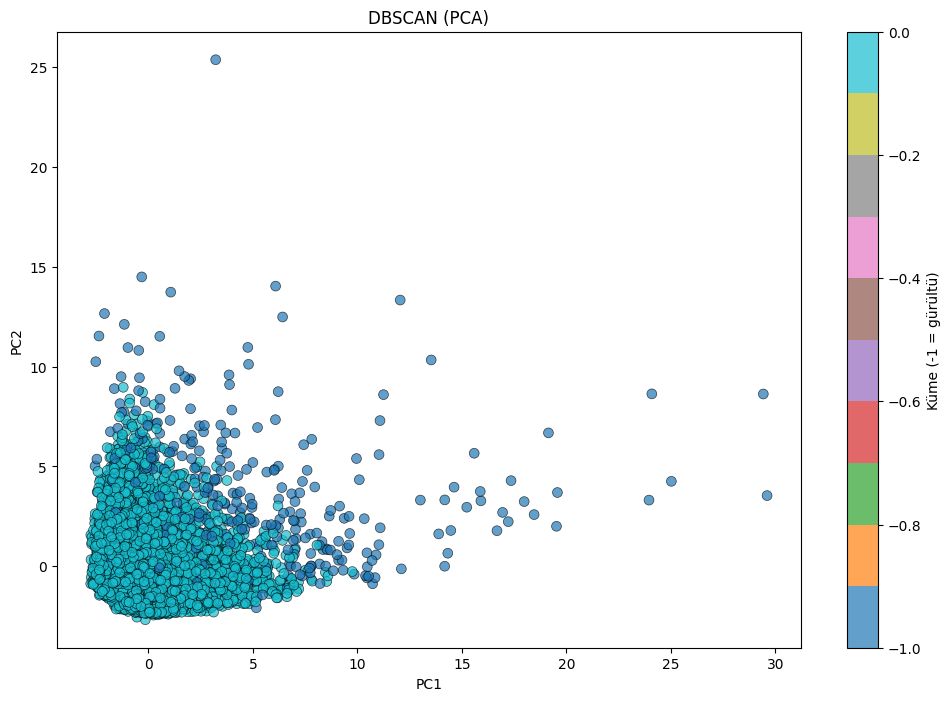

In [41]:
plt.figure(figsize=(12,8))
scatter = plt.scatter(X_pca[:,0],X_pca[:,1],c=dbscan_labels,cmap="tab10",alpha=0.7,s=50,edgecolors="k",linewidth=0.5)
plt.colorbar(scatter,label="Küme (-1 = gürültü)")
plt.title("DBSCAN (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

#### Decision Tree

In [42]:
import random
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split,GridSearchCV,StratifiedKFold,cross_val_score
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [43]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

data = load_breast_cancer()
X = data.data
y = data.target

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=SEED)

In [44]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
                       param_grid={
                           "criterion":["gini","entropy"],
                           "splitter":["best","random"],
                           "max_depth":[3,4,5,6,8,None],
                           "min_samples_leaf":[1,2,5,10]
                       },
                       cv=cv,scoring="accuracy",n_jobs=-1)
dt_grid.fit(X_train,y_train)
dt = dt_grid.best_estimator_
print("En iyi parametre:", dt_grid.best_params_)

En iyi parametre: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 5, 'splitter': 'random'}


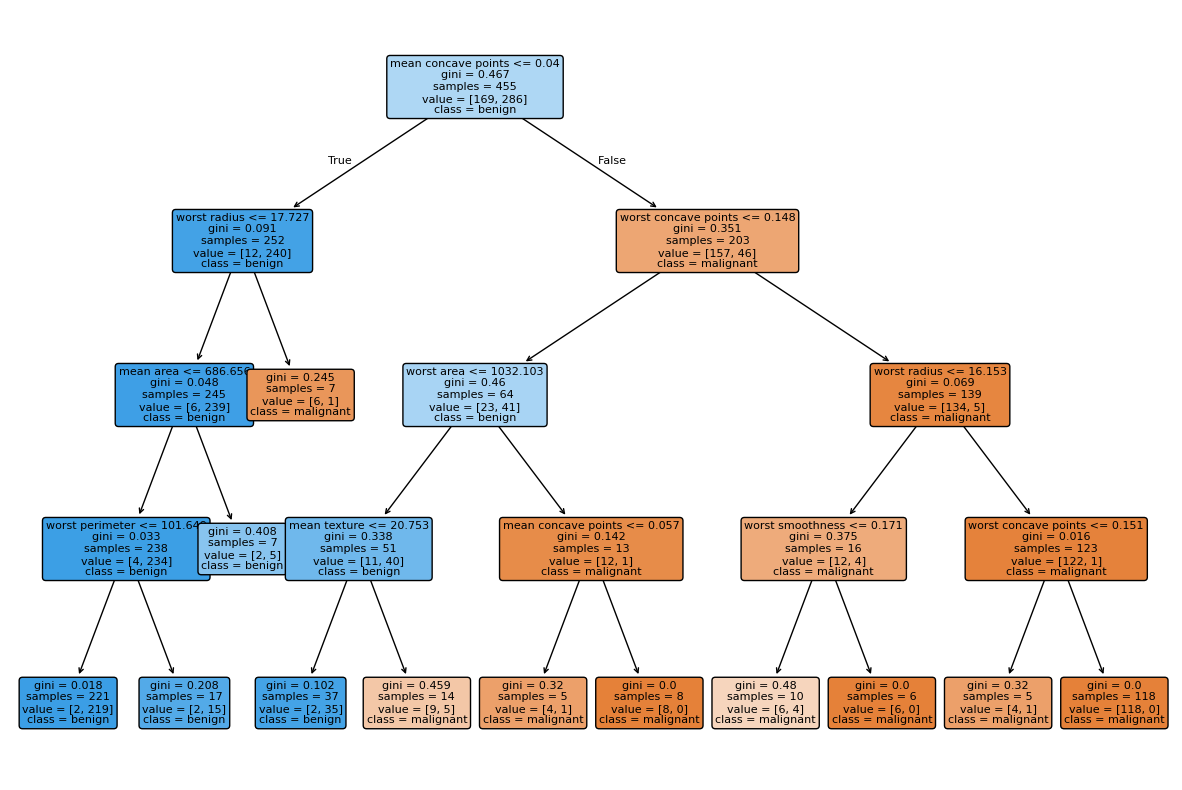

In [45]:
plt.figure(figsize=(15,10))
plot_tree(dt,feature_names=data.feature_names,class_names=data.target_names,filled=True,rounded=True,max_depth=8,fontsize=8)
plt.show()

#### Random Forest

In [46]:
rf_grid = GridSearchCV(RandomForestClassifier(random_state=SEED),
                       param_grid={
                           "n_estimators":[100,200],
                           "max_depth":[5,7],
                           "min_samples_leaf":[1,2],
                           "min_samples_split":[2,5],
                           "max_features":["sqrt","log2"],
                           "criterion":["gini","entropy"],
                           "bootstrap":[True,False]
                       },
                       cv=cv,scoring="accuracy",n_jobs=-1)
rf_grid.fit(X_train,y_train)
rf = rf_grid.best_estimator_
print("En iyi parametre:", rf_grid.best_params_)

En iyi parametre: {'bootstrap': False, 'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


In [47]:
for name,model in [("Decision Tree",dt),("Random Forest",rf)]:
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    cv_scores = cross_val_score(model,X_train,y_train,cv=cv,scoring="accuracy")
    print("=====",name,"=====")
    print("Test doğruluğu:", accuracy_score(y_test,y_pred))
    print("Ortalama 5 katlı CV doğruluğu:", np.mean(cv_scores))

===== Decision Tree =====
Test doğruluğu: 0.9473684210526315
Ortalama 5 katlı CV doğruluğu: 0.9472527472527472
===== Random Forest =====
Test doğruluğu: 0.9649122807017544
Ortalama 5 katlı CV doğruluğu: 0.964835164835165


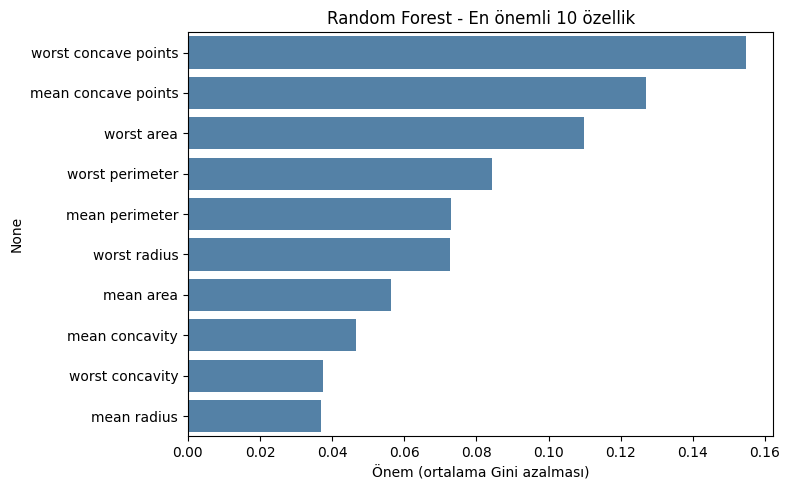

In [48]:
imp = pd.Series(rf.feature_importances_,index=data.feature_names).nlargest(10)
plt.figure(figsize=(8,5))
sns.barplot(x=imp.values,y=imp.index,color="steelblue")
plt.xlabel("Önem (ortalama Gini azalması)")
plt.title("Random Forest - En önemli 10 özellik")
plt.tight_layout()
plt.show()

#### Ensemble modelleri karşılaştıralım

In [49]:
!pip install catboost


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\emir\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [4]:
import time
from sklearn.model_selection import cross_validate
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier,HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

data = load_breast_cancer(as_frame=True)
X,y = data.data,data.target
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=SEED)
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)

ModuleNotFoundError: No module named 'xgboost'

In [2]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),n_estimators=300,learning_rate=0.01,random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300,learning_rate=0.01,max_depth=3,subsample=0.8,random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300,learning_rate=0.05,max_depth=4,subsample=0.8,colsample_bytree=0.8,reg_lambda=1.0,
    eval_metric="logloss",random_state=SEED,n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300,learning_rate=0.05,num_leaves=15,subsample=0.8,subsample_freq=1,colsample_bytree=0.8,
    random_state=SEED,verbose=-1,n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=300,learning_rate=0.05,depth=4,random_seed=SEED,verbose=0),
}

NameError: name 'RandomForestClassifier' is not defined

In [3]:
rows = []
for name,model in models.items():
    t0 = time.time()
    cvr = cross_validate(model,X,y,cv=cv,scoring=["accuracy","roc_auc"],n_jobs=1)
    model.fit(X_train,y_train)
    proba = model.predict_proba(X_test)[:,1]
    pred = (proba>=0.5).astype(int)
    rows.append({
        "Model": name,
        "CV Acc": cvr["test_accuracy"].mean(),
        "CV Acc Std": cvr["test_accuracy"].std(),
        "CV AUC": cvr["test_roc_auc"].mean(),
        "Test Acc": accuracy_score(y_test,pred),
        "Test AUC": roc_auc_score(y_test,proba),
        "Süre (s)": time.time()-t0,
    })
    print(name,"tamamlandı")

results = pd.DataFrame(rows).sort_values("CV AUC",ascending=False).reset_index(drop=True)
results

NameError: name 'models' is not defined